# Experiment 1 analysis: learning curves and the small-data regime

This notebook analyses results/tables/experiment_1.csv. It first reports mean and sample standard deviation over repeated runs for every dataset, model, training size, and recorded metric. It then shows a two-dataset-column by six-metric-row learning-curve grid and several views focused on the central question: how do neural-network and Gaussian-process approaches compare when data are scarce?

Method families used in the focused comparisons:

- Pure GP: exact GP and sparse GP variants
- Pure NN: deep ensemble and MC dropout
- Hybrid: DKL (shown in model-level plots but kept separate from the pure-family comparison)

Lower is better for RMSE, NLL, CRPS, training time, and inference time. For coverage, closeness to the nominal 0.90 target is better.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)

# Work whether the kernel starts in the repository root or in notebooks/.
DATA_CANDIDATES = [
    Path("results/tables/experiment_1_new.csv"),
    Path("../results/tables/experiment_1_new.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find results/tables/experiment_1.csv")

results = pd.read_csv(DATA_PATH)

METRICS = [
    "rmse",
    "nll",
    "crps",
    "coverage_90",
    "final_training_time_seconds",
    "inference_time_seconds",
]
REQUIRED = {"dataset", "split", "train_size", "model", *METRICS}
missing = REQUIRED.difference(results.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

results["train_size"] = pd.to_numeric(results["train_size"])
for metric in METRICS:
    results[metric] = pd.to_numeric(results[metric], errors="coerce")

DATASETS = sorted(results["dataset"].dropna().unique())
TRAIN_SIZES = sorted(results["train_size"].dropna().unique())
MODEL_ORDER = [
    model for model in [
        "exact_gp", "sparse_gp_m16", "sparse_gp_m64", "sparse_gp_m256",
        "deep_ensemble", "mc_dropout", "mc_dropout_standard", "dkl",
    ] if model in set(results["model"])
]
MODEL_ORDER += sorted(set(results["model"]) - set(MODEL_ORDER))

MODEL_LABELS = {
    "exact_gp": "Exact GP",
    "sparse_gp_m16": "Sparse GP (m=16)",
    "sparse_gp_m64": "Sparse GP (m=64)",
    "sparse_gp_m256": "Sparse GP (m=256)",
    "deep_ensemble": "Deep ensemble",
    "mc_dropout": "MC dropout (heteroscedastic)",
    "mc_dropout_standard": "MC dropout (standard)",
    "dkl": "DKL (hybrid)",
}
MODEL_COLORS = dict(zip(MODEL_ORDER, sns.color_palette("tab10", n_colors=len(MODEL_ORDER))))
MODEL_MARKERS = dict(zip(MODEL_ORDER, ["o", "s", "^", "D", "P", "X", "v", "*"][:len(MODEL_ORDER)]))
MODEL_LINESTYLES = dict(zip(MODEL_ORDER, ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1)), (0, (5, 2, 1, 2))][:len(MODEL_ORDER)]))
GP_MODELS = [m for m in MODEL_ORDER if m == "exact_gp" or m.startswith("sparse_gp")]
NN_MODELS = [m for m in MODEL_ORDER if m in {"deep_ensemble", "mc_dropout", "mc_dropout_standard"}]

print(f"Loaded {len(results):,} rows from {DATA_PATH.resolve()}")
print(f"Datasets: {len(DATASETS)} | models: {len(MODEL_ORDER)} | train sizes: {TRAIN_SIZES}")
display(results.groupby(["dataset", "train_size"])["split"].nunique().rename("number_of_runs").to_frame())

Loaded 660 rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/experiment_1_new.csv
Datasets: 3 | models: 8 | train sizes: [50, 100, 200, 400, 800, 1600]


number_of_runs
dataset                    train_size                
combined_cycle_power_plant 50                       5
                           100                      5
                           200                      5
                           400                      5
                           800                      5
                           1600                     5
electrical_grid_stability  50                       5
                           100                      5
                           200                      5
                           400                      5
                           800                      5
                           1600                     5
kin8nm                     50                       5
                           100                      5
                           200                      5
                           400                      5
                           800                      5
                           1600                     5

## Mean ± standard deviation over runs

The table below is grouped by dataset, model, and training size. Every metric is summarized over splits/runs with its arithmetic mean and sample standard deviation (pandas ddof=1). The run count is included to make missing or unbalanced cells visible.

In [9]:
summary = (
    results.groupby(["dataset", "model", "train_size"], observed=True)
    .agg(
        runs=("split", "nunique"),
        **{
            f"{metric}_{stat}": (metric, stat)
            for metric in METRICS
            for stat in ("mean", "std")
        },
    )
    .sort_index()
)

display(summary.round(4))

runs  rmse_mean  \
dataset                    model               train_size                    
combined_cycle_power_plant deep_ensemble       50             5     4.7208   
                                               100            5     4.7830   
                                               200            5     4.3051   
                                               400            5     4.2471   
                                               800            5     4.1755   
                                               1600           5     4.1368   
                           dkl                 50             5     5.4437   
                                               100            5     5.0754   
                                               200            5     4.6317   
                                               400            5     4.3878   
                                               800            5     4.2453   
                                               1600           5     4.1448   
                           exact_gp            50             5     5.9018   
                                               100            5     5.4225   
                                               200            5     4.8193   
                                               400            5     4.5660   
                                               800            5     4.2689   
                                               1600           5     4.0606   
                           mc_dropout          50             5     5.8355   
                                               100            5     5.5873   
                                               200            5     5.3623   
                                               400            5     4.8682   
                                               800            5     4.7985   
                                               1600           5     4.7263   
                           mc_dropout_standard 50             5     5.8714   
                                               100            5     5.3083   
                                               200            5     4.7845   
                                               400            5     4.5894   
                                               800            5     4.4554   
                                               1600           5     4.4205   
                           sparse_gp_m16       50             5     6.4983   
                                               100            5     6.1750   
                                               200            5     4.5283   
                                               400            5     4.3162   
                                               800            5     4.2106   
                                               1600           5     4.1971   
                           sparse_gp_m256      400            5     4.2798   
                                               800            5     4.1641   
                                               1600           5     4.0771   
                           sparse_gp_m64       100            5     5.5291   
                                               200            5     4.4623   
                                               400            5     4.2831   
                                               800            5     4.1918   
                                               1600           5     4.1357   
electrical_grid_stability  deep_ensemble       50             5     0.0236   
                                               100            5     0.0200   
                                               200            5     0.0159   
                                               400            5     0.0121   
                                               800            5     0.0103   
                                               1600           5     0.0082   
   

## Learning curves: all six metrics

Each column is one dataset and each row is one metric. Lines show run means without uncertainty ribbons; the exact standard deviations are reported in the summary table above. Coincident curves use distinct marker shapes and line styles while retaining the original colors and exact training-size positions. The x-axis uses a base-2 log scale because the training sizes double. Timing panels use a logarithmic y-axis.

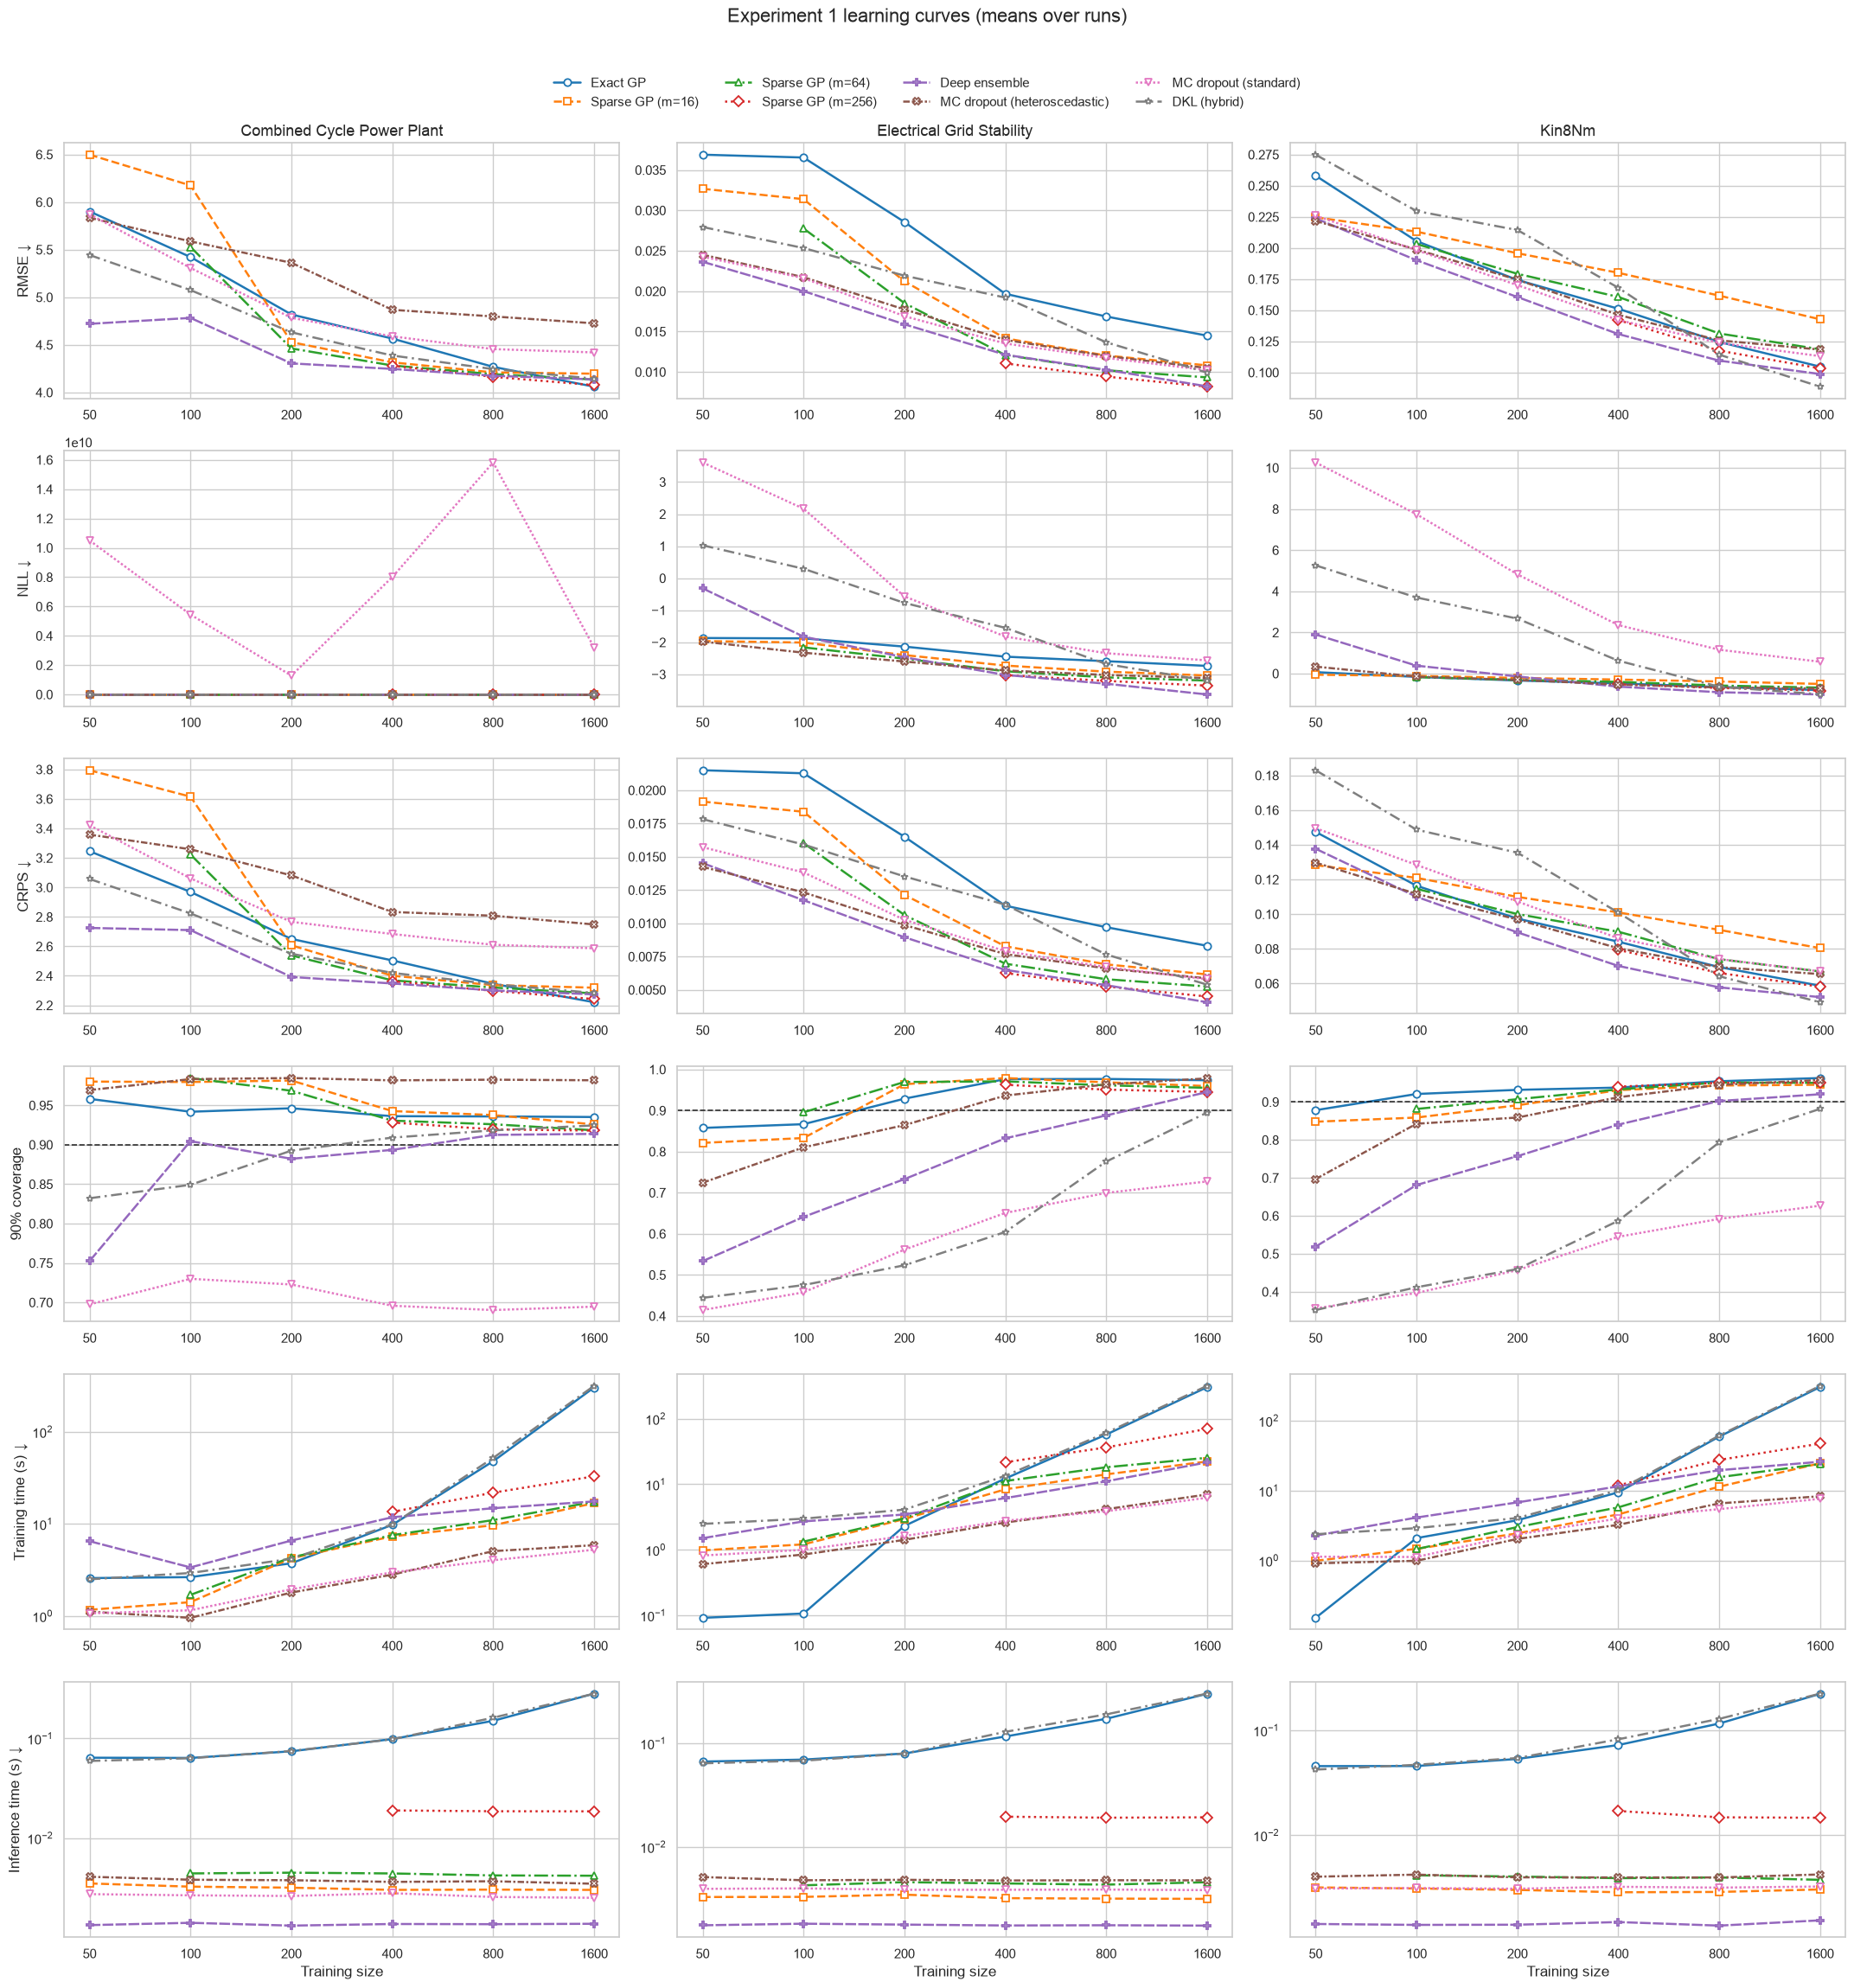

In [10]:
metric_specs = {
    "rmse": ("RMSE ↓", False),
    "nll": ("NLL ↓", False),
    "crps": ("CRPS ↓", False),
    "coverage_90": ("90% coverage", False),
    "final_training_time_seconds": ("Training time (s) ↓", True),
    "inference_time_seconds": ("Inference time (s) ↓", True),
}

curve_stats = (
    results.groupby(["dataset", "model", "train_size"], observed=True)[METRICS]
    .agg(["mean", "std"])
    .sort_index()
)

fig, axes = plt.subplots(
    len(metric_specs), len(DATASETS),
    figsize=(7.2 * len(DATASETS), 3.7 * len(metric_specs)),
    squeeze=False,
)

for row, (metric, (ylabel, log_y)) in enumerate(metric_specs.items()):
    for col, dataset in enumerate(DATASETS):
        ax = axes[row, col]
        for model in MODEL_ORDER:
            try:
                current = curve_stats.loc[(dataset, model)]
            except KeyError:
                continue
            x = current.index.to_numpy(dtype=float)
            mean = current[(metric, "mean")].to_numpy(dtype=float)
            valid = np.isfinite(x) & np.isfinite(mean)
            x, mean = x[valid], mean[valid]
            if not len(x):
                continue
            color = MODEL_COLORS[model]
            ax.plot(x, mean, marker=MODEL_MARKERS[model],
                    linestyle=MODEL_LINESTYLES[model], linewidth=1.8, markersize=6,
                    color=color, markerfacecolor="white", markeredgecolor=color,
                    markeredgewidth=1.3, zorder=2 + MODEL_ORDER.index(model),
                    label=MODEL_LABELS.get(model, model))

        ax.set_xscale("log", base=2)
        ax.set_xticks(TRAIN_SIZES)
        ax.set_xticklabels([str(int(x)) for x in TRAIN_SIZES])
        if log_y:
            ax.set_yscale("log")
        if metric == "coverage_90":
            ax.axhline(0.90, color="black", linestyle="--", linewidth=1.2, alpha=0.8)
        if row == 0:
            ax.set_title(dataset.replace("_", " ").title(), fontsize=13)
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == len(metric_specs) - 1:
            ax.set_xlabel("Training size")

handles = [
    Line2D([0], [0], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m],
           linestyle=MODEL_LINESTYLES[m], markerfacecolor="white",
           markeredgecolor=MODEL_COLORS[m], markeredgewidth=1.3, linewidth=1.8,
           label=MODEL_LABELS.get(m, m))
    for m in MODEL_ORDER
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.005),
           ncol=min(4, len(handles)), frameon=False)
fig.suptitle("Experiment 1 learning curves (means over runs)", y=1.035, fontsize=16)
fig.tight_layout()
plt.show()

## Direct GP-versus-NN comparison

For each dataset, size, and predictive metric, this selects the best run-averaged pure GP and pure NN. Coverage is converted to absolute calibration error, |coverage − 0.90|. Positive values favor GPs; negative values favor NNs. DKL remains separate as a hybrid.

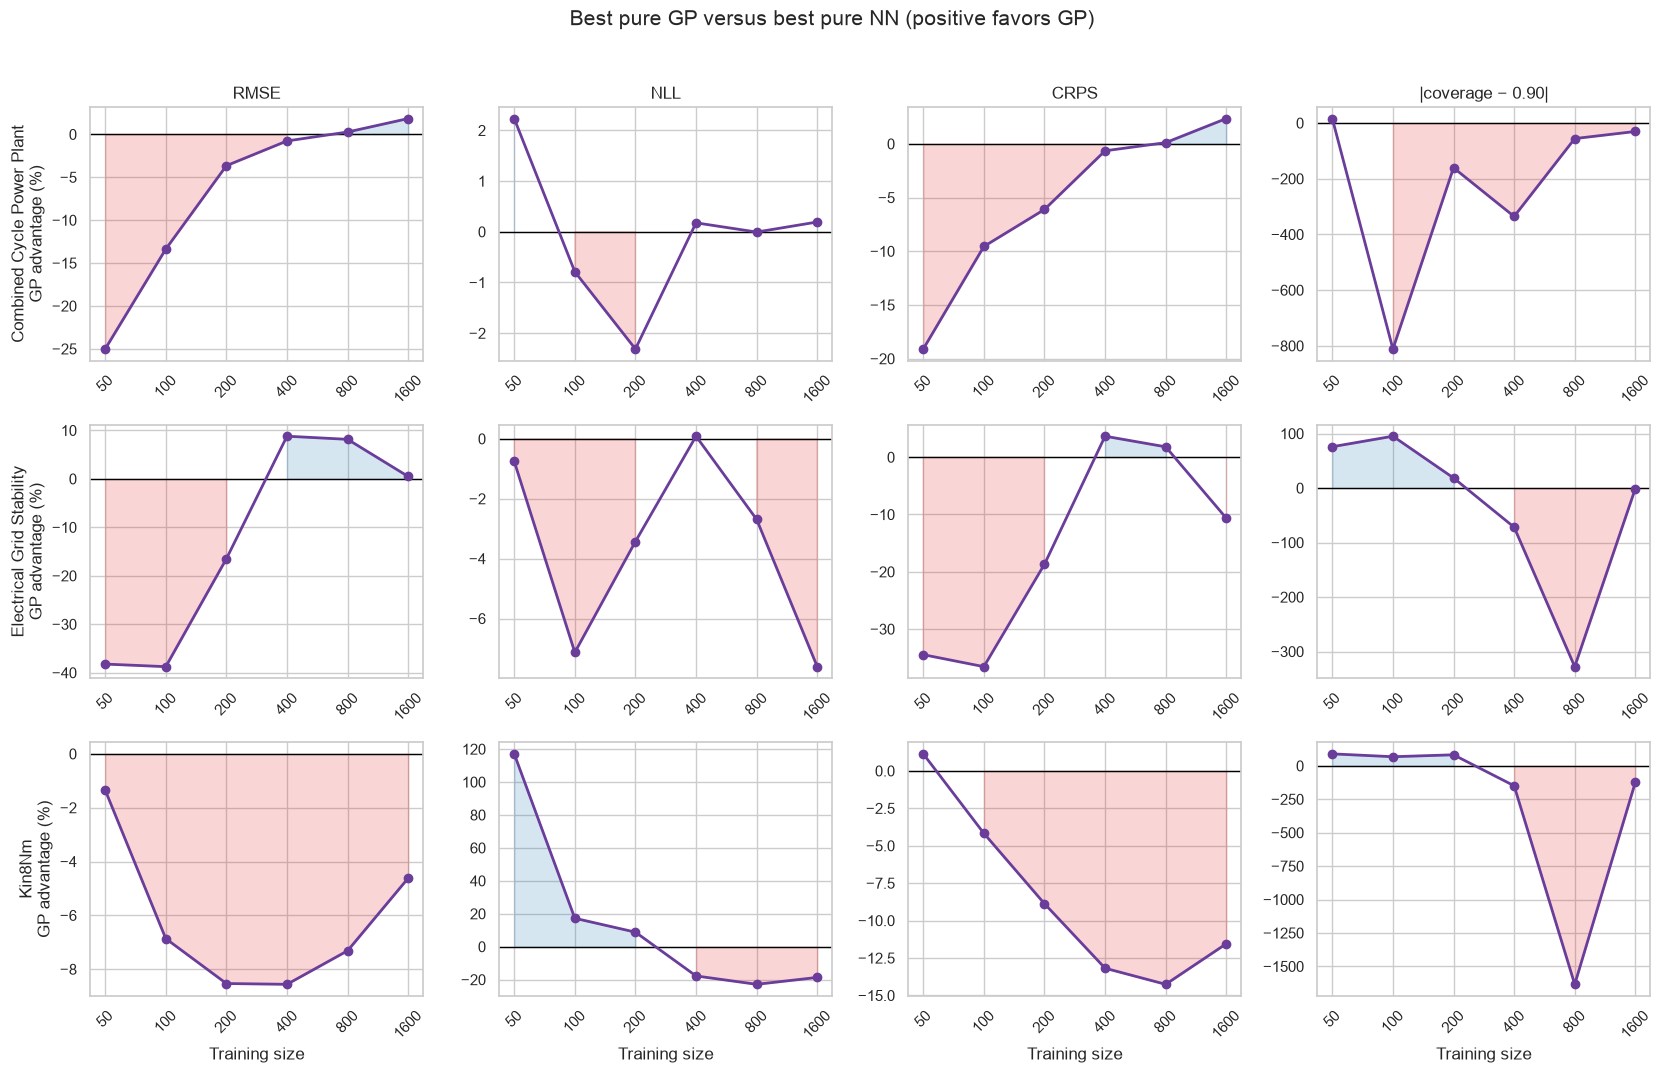

comparisons  gp_win_rate_pct  \
dataset                    metric                                         
combined_cycle_power_plant coverage_error            3            33.33   
                           crps                      3             0.00   
                           nll                       3            33.33   
                           rmse                      3             0.00   
electrical_grid_stability  coverage_error            3           100.00   
                           crps                      3             0.00   
                           nll                       3             0.00   
                           rmse                      3             0.00   
kin8nm                     coverage_error            3           100.00   
                           crps                      3            33.33   
                           nll                       3           100.00   
                           rmse                      3             0.00   

                                           mean_gp_advantage_pct  \
dataset                    metric                                  
combined_cycle_power_plant coverage_error                -318.61   
                           crps                           -11.59   
                           nll                             -0.29   
                           rmse                           -14.01   
electrical_grid_stability  coverage_error                  63.23   
                           crps                           -29.90   
                           nll                             -3.77   
                           rmse                           -31.16   
kin8nm                     coverage_error                  79.87   
                           crps                            -3.97   
                           nll                             47.72   
                           rmse                            -5.58   

                                           median_gp_advantage_pct  
dataset                    metric                                   
combined_cycle_power_plant coverage_error                  -160.59  
                           crps                              -9.55  
                           nll                               -0.79  
                           rmse                             -13.37  
electrical_grid_stability  coverage_error                    75.91  
                           crps                             -34.47  
                           nll                               -3.43  
                           rmse                             -38.22  
kin8nm                     coverage_error                    82.32  
                           crps                              -4.17  
                           nll                               17.26  
                           rmse                              -6.86

In [11]:
model_means = results.groupby(["dataset", "train_size", "model"], observed=True)[METRICS].mean().reset_index()
model_means["coverage_error"] = (model_means["coverage_90"] - 0.90).abs()
COMPARE_METRICS = ["rmse", "nll", "crps", "coverage_error"]
COMPARE_LABELS = {"rmse": "RMSE", "nll": "NLL", "crps": "CRPS", "coverage_error": "|coverage − 0.90|"}

rows = []
for (dataset, train_size), current in model_means.groupby(["dataset", "train_size"], observed=True):
    for metric in COMPARE_METRICS:
        gp = current[current["model"].isin(GP_MODELS)].dropna(subset=[metric])
        nn = current[current["model"].isin(NN_MODELS)].dropna(subset=[metric])
        if gp.empty or nn.empty: continue
        gp_best, nn_best = gp.loc[gp[metric].idxmin()], nn.loc[nn[metric].idxmin()]
        denominator = max(abs(float(nn_best[metric])), np.finfo(float).eps)
        rows.append({"dataset": dataset, "train_size": train_size, "metric": metric,
                     "best_gp": gp_best["model"], "gp_score": gp_best[metric],
                     "best_nn": nn_best["model"], "nn_score": nn_best[metric],
                     "gp_advantage_pct": 100 * (nn_best[metric] - gp_best[metric]) / denominator})
family_comparison = pd.DataFrame(rows)

fig, axes = plt.subplots(len(DATASETS), len(COMPARE_METRICS),
                         figsize=(4.2 * len(COMPARE_METRICS), 3.5 * len(DATASETS)), squeeze=False)
for row, dataset in enumerate(DATASETS):
    for col, metric in enumerate(COMPARE_METRICS):
        ax = axes[row, col]
        current = family_comparison[(family_comparison["dataset"] == dataset) &
                                    (family_comparison["metric"] == metric)].sort_values("train_size")
        ax.axhline(0, color="black", linewidth=1)
        ax.plot(current["train_size"], current["gp_advantage_pct"], marker="o", color="#6a3d9a", linewidth=2)
        ax.fill_between(current["train_size"], 0, current["gp_advantage_pct"],
                        where=current["gp_advantage_pct"] >= 0, color="#1f78b4", alpha=0.18)
        ax.fill_between(current["train_size"], 0, current["gp_advantage_pct"],
                        where=current["gp_advantage_pct"] < 0, color="#e31a1c", alpha=0.18)
        ax.set_xscale("log", base=2); ax.set_xticks(TRAIN_SIZES)
        ax.set_xticklabels([str(int(x)) for x in TRAIN_SIZES], rotation=45)
        if row == 0: ax.set_title(COMPARE_LABELS[metric])
        if col == 0: ax.set_ylabel(dataset.replace("_", " ").title() + "\nGP advantage (%)")
        if row == len(DATASETS) - 1: ax.set_xlabel("Training size")
fig.suptitle("Best pure GP versus best pure NN (positive favors GP)", y=1.02, fontsize=15)
fig.tight_layout(); plt.show()

SMALL_DATA_MAX = 200
small_answer = (family_comparison[family_comparison["train_size"] <= SMALL_DATA_MAX]
    .groupby(["dataset", "metric"], observed=True)
    .agg(comparisons=("gp_advantage_pct", "size"),
         gp_win_rate_pct=("gp_advantage_pct", lambda x: 100 * (x > 0).mean()),
         mean_gp_advantage_pct=("gp_advantage_pct", "mean"),
         median_gp_advantage_pct=("gp_advantage_pct", "median")))
display(small_answer.round(2))

## Small-data average-rank heatmap

For sizes up to 200, models are ranked within every dataset × size × metric task for RMSE, NLL, CRPS, and calibration error. Lower average rank is better; n states how many tasks contributed.

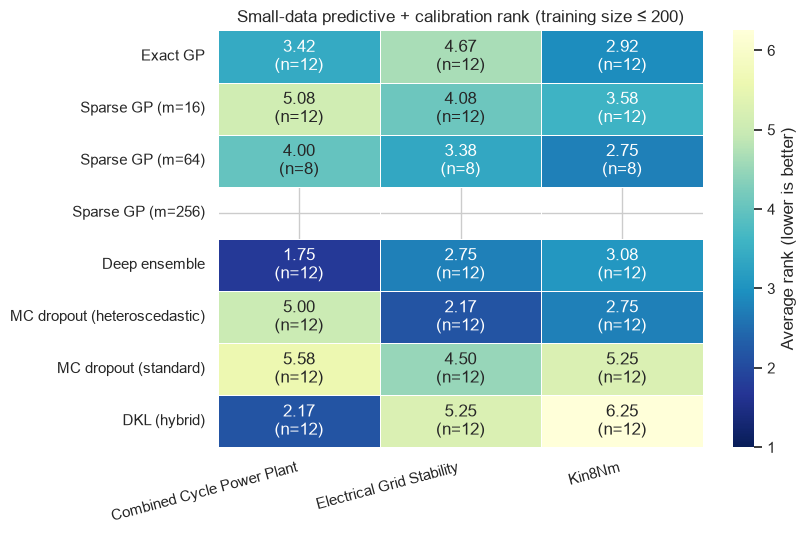

In [12]:
small = model_means[model_means["train_size"] <= SMALL_DATA_MAX].copy()
rank_parts = []
for metric in COMPARE_METRICS:
    part = small[["dataset", "train_size", "model", metric]].dropna().copy()
    part["rank"] = part.groupby(["dataset", "train_size"], observed=True)[metric].rank(method="average")
    rank_parts.append(part[["dataset", "train_size", "model", "rank"]])
ranks = pd.concat(rank_parts, ignore_index=True)
rank_summary = (ranks.groupby(["model", "dataset"], observed=True)
                .agg(average_rank=("rank", "mean"), tasks=("rank", "size")).reset_index())
rank_matrix = rank_summary.pivot(index="model", columns="dataset", values="average_rank").reindex(MODEL_ORDER)
task_matrix = rank_summary.pivot(index="model", columns="dataset", values="tasks").reindex(MODEL_ORDER)
annotations = rank_matrix.copy().astype(object)
for model in rank_matrix.index:
    for dataset in rank_matrix.columns:
        value, count = rank_matrix.loc[model, dataset], task_matrix.loc[model, dataset]
        annotations.loc[model, dataset] = "" if pd.isna(value) else f"{value:.2f}\n(n={int(count)})"
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(rank_matrix, annot=annotations, fmt="", cmap="YlGnBu_r", vmin=1,
            linewidths=0.5, cbar_kws={"label": "Average rank (lower is better)"}, ax=ax)
ax.set_yticklabels([MODEL_LABELS.get(m, m) for m in rank_matrix.index], rotation=0)
ax.set_xticklabels([d.replace("_", " ").title() for d in rank_matrix.columns], rotation=15, ha="right")
ax.set(xlabel="", ylabel="", title=f"Small-data predictive + calibration rank (training size ≤ {SMALL_DATA_MAX})")
plt.tight_layout(); plt.show()

## Small-data accuracy–cost frontier

Mean RMSE is plotted against mean final training time for sizes 50, 100, and 200. Lower-left is preferable. Color identifies the model and marker shape identifies size.

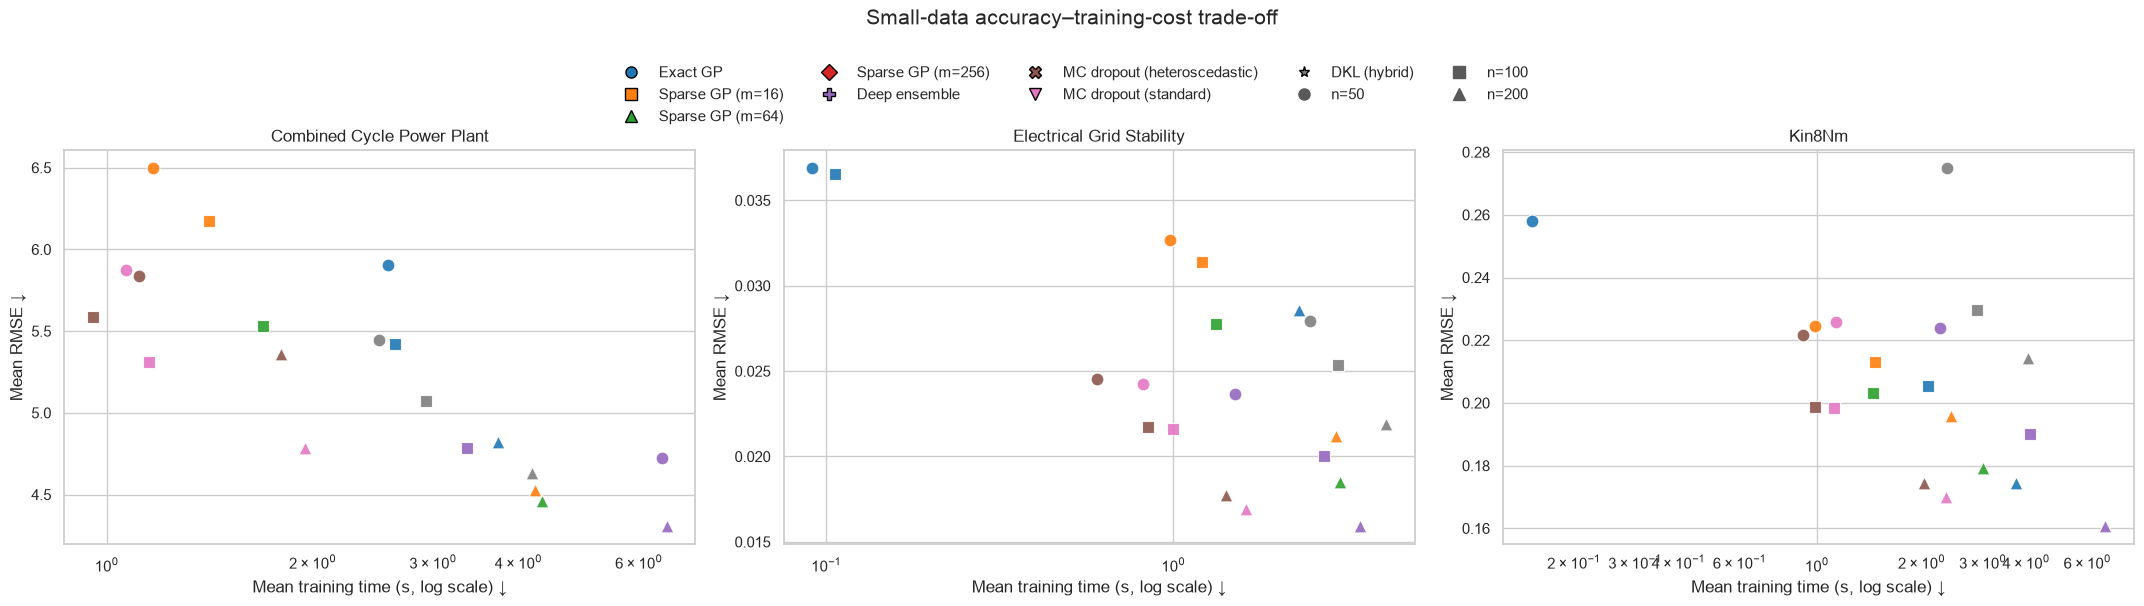

In [13]:
pareto = model_means[model_means["train_size"] <= SMALL_DATA_MAX].copy()
small_sizes = sorted(pareto["train_size"].unique())
size_markers = dict(zip(small_sizes, ["o", "s", "^"][:len(small_sizes)]))
fig, axes = plt.subplots(1, len(DATASETS), figsize=(7.2 * len(DATASETS), 5.4), squeeze=False)
for ax, dataset in zip(axes[0], DATASETS):
    current = pareto[pareto["dataset"] == dataset]
    for model in MODEL_ORDER:
        for train_size in small_sizes:
            point = current[(current["model"] == model) & (current["train_size"] == train_size)]
            if not point.empty:
                ax.scatter(point["final_training_time_seconds"], point["rmse"],
                           color=MODEL_COLORS[model], marker=size_markers[train_size], s=85,
                           alpha=0.9, edgecolor="white", linewidth=0.8)
    ax.set_xscale("log")
    ax.set(xlabel="Mean training time (s, log scale) ↓", ylabel="Mean RMSE ↓",
           title=dataset.replace("_", " ").title())
model_handles = [Line2D([0], [0], marker=MODEL_MARKERS[m], color="none",
                        markerfacecolor=MODEL_COLORS[m], markersize=8,
                        label=MODEL_LABELS.get(m, m)) for m in MODEL_ORDER]
size_handles = [Line2D([0], [0], marker=size_markers[n], color="0.35", linestyle="none",
                       markersize=8, label=f"n={int(n)}") for n in small_sizes]
fig.legend(handles=model_handles + size_handles, loc="upper center", bbox_to_anchor=(0.5, 1.04),
           ncol=5, frameon=False)
fig.suptitle("Small-data accuracy–training-cost trade-off", y=1.12, fontsize=15)
fig.tight_layout(); plt.show()

### Interpretation notes

- Standard deviations remain in the table instead of overlapping ribbons.
- Learning curves use the exact training sizes without horizontal offsets.
- Best-in-family comparisons are descriptive and benefit families with more candidate configurations.
- DKL is kept separate because it combines a neural feature extractor with a GP output layer.